# 01b – First look at the data

**Purpose:** a first look at the raw IFData files downloaded by `01_get_data.py`, before cleaning:
how much data there is, what the target looks like, and which anomalies the cleaning stage must handle.

**Input:** `data/raw/ifdata_risk_level_type2.csv.gz` (loans by risk rating AA–H, financial conglomerates
and independent institutions, quarterly).
**Output:** 4 figures in `figures/`, nothing else is changed.

*Attribution: drafted with Claude (Anthropic) to prepare the proposal meeting; reviewed by me.*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Find the project folder, whether the notebook runs from code/ or from the project root
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
RAW = ROOT / "data" / "raw"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

MIN_LOANS = 10_000_000  # R$ 10 million: provisional minimum loan portfolio, to be decided in cleaning

## 1. Load the file and reshape it

The raw file is in **long format**: one row per institution × rating category × quarter.
`pivot_table` turns it into **one row per institution per quarter**, with one column per rating.

In [2]:
raw = pd.read_csv(RAW / "ifdata_risk_level_type2.csv.gz")
print(f"Raw file: {len(raw):,} rows (long format)")

loans = raw.pivot_table(index=["CodInst", "quarter"], columns="NomeColuna",
                        values="Saldo", aggfunc="sum").reset_index()
loans = loans.rename(columns={"CodInst": "bank_id", "Total Geral": "total_loans"})
print(f"Reshaped: {len(loans):,} bank-quarters, {loans['bank_id'].nunique():,} institutions")
loans.head()

Raw file: 663,245 rows (long format)
Reshaped: 60,282 bank-quarters, 2,036 institutions


NomeColuna,bank_id,quarter,A,AA,B,C,D,E,F,G,H,Total Exterior,total_loans
0,00058338,201406,674697.76,0.0,247689.46,65795.37,302.66,6372.48,5186.24,10392.74,34691.82,0.0,1045128.53
1,00058338,201409,641256.68,0.0,202151.85,25382.67,3891.57,17066.19,25083.33,1462.62,34883.31,0.0,951178.22
2,00058338,201412,672811.78,0.0,156851.61,31499.00,35524.88,15227.45,6910.31,1376.09,64360.96,0.0,984562.08
3,00058338,201503,762783.04,0.0,170377.85,24058.80,12800.99,6221.57,6344.67,16672.78,58141.35,0.0,1057401.05
4,00058338,201506,692984.15,0.0,156897.93,28245.62,17698.82,4711.10,3903.41,5198.63,62402.89,0.0,972042.55


## 2. Build the target: share of high-risk loans

**High-risk share = (E + F + G + H) / total loans.** Rating E starts at 91 days late, close to the
usual non-performing loan definition (> 90 days past due).

In [3]:
loans = loans[loans["total_loans"] > 0].copy()  # cannot divide by zero
loans["high_risk_share"] = loans[["E", "F", "G", "H"]].sum(axis=1) / loans["total_loans"]

# Next quarter's share for the same bank = my Y
loans = loans.sort_values(["bank_id", "quarter"])
quarters = sorted(loans["quarter"].unique())
next_q = {q: quarters[i + 1] for i, q in enumerate(quarters[:-1])}
loans["next_quarter"] = loans["quarter"].map(next_q)
nxt = loans[["bank_id", "quarter", "high_risk_share"]].rename(
    columns={"quarter": "next_quarter", "high_risk_share": "y_next"})
loans = loans.merge(nxt, on=["bank_id", "next_quarter"], how="left")

loans["high_risk_share"].describe(percentiles=[0.1, 0.5, 0.9]).round(3)

count    51172.000
mean         0.069
std          0.095
min          0.000
10%          0.002
50%          0.044
90%          0.147
max          1.000
Name: high_risk_share, dtype: float64

## 3. Anomalies found

Each anomaly below has a figure or a number, and a planned fix for the cleaning stage.

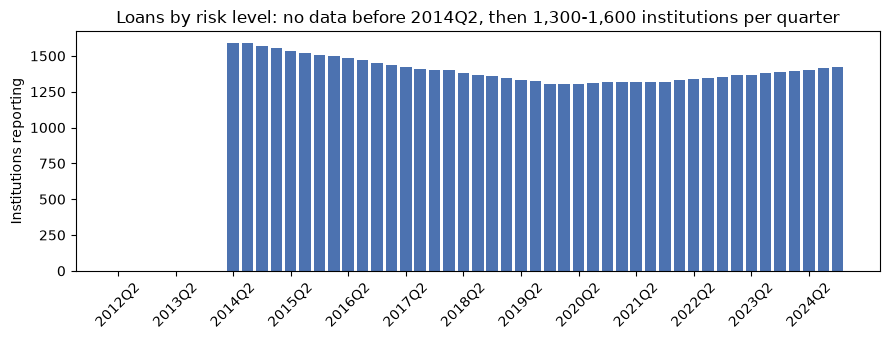

In [4]:
# Anomaly 1 – coverage: how many institutions report each quarter?
all_quarters = [y * 100 + m for y in range(2012, 2025) for m in (3, 6, 9, 12) if not (y == 2012 and m == 3)]
count = raw.groupby("quarter")["CodInst"].nunique().reindex(all_quarters, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 3.5))
labels = [f"{q // 100}Q{(q % 100) // 3}" for q in count.index]
ax.bar(labels, count.values, color=["#c44e52" if v == 0 else "#4c72b0" for v in count.values])
ax.set_xticks(range(0, len(labels), 4))
ax.set_xticklabels(labels[::4], rotation=45)
ax.set_ylabel("Institutions reporting")
ax.set_title("Loans by risk level: no data before 2014Q2, then 1,300-1,600 institutions per quarter")
fig.tight_layout()
fig.savefig(FIG / "first_look_1_coverage.png", dpi=150)
plt.show()

Bank-quarters with exactly 0% high-risk loans: 8.0%
  among lenders below R$ 10 million:  16.7%
  among lenders above R$ 10 million:  4.7%
Bank-quarters with more than 50% high-risk loans: 0.9%


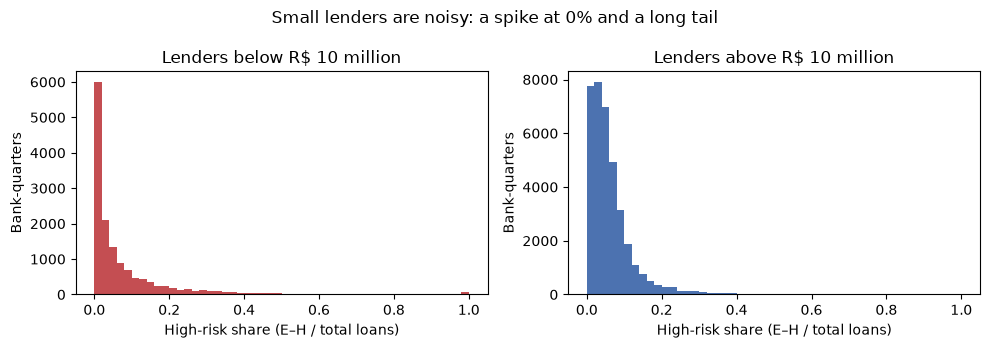

In [5]:
# Anomaly 2 – tiny lenders: many exact zeros and extreme values
small = loans["total_loans"] < MIN_LOANS
print(f"Bank-quarters with exactly 0% high-risk loans: {(loans['high_risk_share'] == 0).mean():.1%}")
print(f"  among lenders below R$ 10 million:  {(loans.loc[small, 'high_risk_share'] == 0).mean():.1%}")
print(f"  among lenders above R$ 10 million:  {(loans.loc[~small, 'high_risk_share'] == 0).mean():.1%}")
print(f"Bank-quarters with more than 50% high-risk loans: {(loans['high_risk_share'] > 0.5).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=False)
axes[0].hist(loans.loc[small, "high_risk_share"], bins=50, color="#c44e52")
axes[0].set_title("Lenders below R$ 10 million")
axes[1].hist(loans.loc[~small, "high_risk_share"], bins=50, color="#4c72b0")
axes[1].set_title("Lenders above R$ 10 million")
for ax in axes:
    ax.set_xlabel("High-risk share (E–H / total loans)")
    ax.set_ylabel("Bank-quarters")
fig.suptitle("Small lenders are noisy: a spike at 0% and a long tail")
fig.tight_layout()
fig.savefig(FIG / "first_look_2_distribution.png", dpi=150)
plt.show()

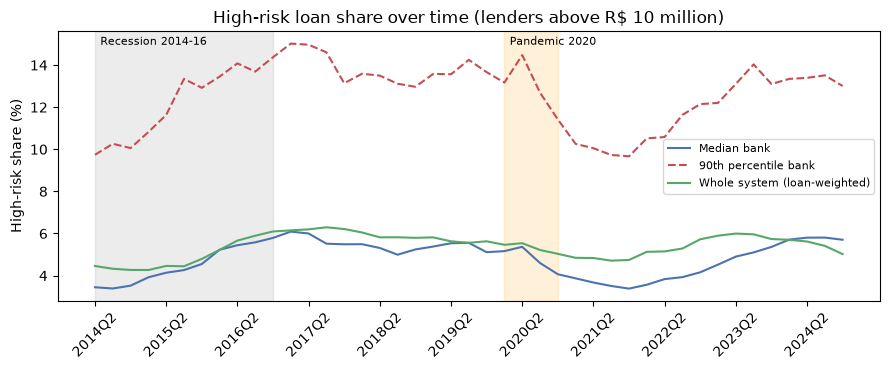

,median,p90,system
quarter,,,
201406,3.4,9.7,4.5
201506,4.1,11.6,4.5
201606,5.4,14.1,5.7
201706,6.0,15.0,6.2
201806,5.3,13.5,5.8
201906,5.5,13.6,5.6
202006,5.4,14.5,5.5
202106,3.7,10.1,4.8
202206,3.8,10.6,5.1


In [6]:
# Anomaly 3 – the target moves with the economy (2014-16 recession, 2020 pandemic)
big = loans[~small]
by_q = big.groupby("quarter")
trend = pd.DataFrame({
    "median": by_q["high_risk_share"].median(),
    "p90": by_q["high_risk_share"].quantile(0.9),
    "system": by_q.apply(lambda d: d[["E", "F", "G", "H"]].sum().sum() / d["total_loans"].sum()),
})
x = range(len(trend))
labels = [f"{q // 100}Q{(q % 100) // 3}" for q in trend.index]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(x, trend["median"] * 100, label="Median bank", color="#4c72b0")
ax.plot(x, trend["p90"] * 100, label="90th percentile bank", color="#c44e52", linestyle="--")
ax.plot(x, trend["system"] * 100, label="Whole system (loan-weighted)", color="#55a868")
ax.axvspan(labels.index("2014Q2"), labels.index("2016Q4"), color="grey", alpha=0.15)
ax.axvspan(labels.index("2020Q1"), labels.index("2020Q4"), color="orange", alpha=0.15)
ax.text(labels.index("2014Q2") + 0.3, 0.95, "Recession 2014-16", fontsize=8, transform=ax.get_xaxis_transform())
ax.text(labels.index("2020Q1") + 0.3, 0.95, "Pandemic 2020", fontsize=8, transform=ax.get_xaxis_transform())
ax.set_xticks(list(x)[::4])
ax.set_xticklabels(labels[::4], rotation=45)
ax.set_ylabel("High-risk share (%)")
ax.set_title("High-risk loan share over time (lenders above R$ 10 million)")
ax.legend(fontsize=8, loc="center right")
fig.tight_layout()
fig.savefig(FIG / "first_look_3_over_time.png", dpi=150)
plt.show()
trend.iloc[::4].mul(100).round(1)

Correlation between this quarter and next quarter: 0.94  (35,680 bank-quarters)
Typical size of the level: 0.069; of the quarterly change: 0.025


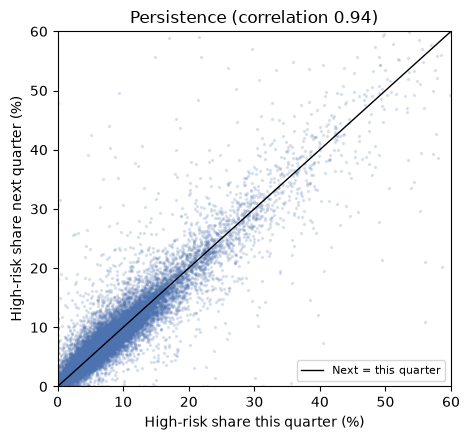

In [7]:
# Anomaly 4 – strong persistence: this quarter's share almost equals next quarter's
pairs = big.dropna(subset=["y_next"])
corr = pairs["high_risk_share"].corr(pairs["y_next"])
print(f"Correlation between this quarter and next quarter: {corr:.2f}  ({len(pairs):,} bank-quarters)")
print(f"Typical size of the level: {pairs['high_risk_share'].std():.3f}; "
      f"of the quarterly change: {(pairs['y_next'] - pairs['high_risk_share']).std():.3f}")

fig, ax = plt.subplots(figsize=(4.8, 4.5))
ax.scatter(pairs["high_risk_share"] * 100, pairs["y_next"] * 100, s=2, alpha=0.15, color="#4c72b0")
ax.plot([0, 100], [0, 100], color="black", linewidth=1, label="Next = this quarter")
ax.set_xlim(0, 60)
ax.set_ylim(0, 60)
ax.set_xlabel("High-risk share this quarter (%)")
ax.set_ylabel("High-risk share next quarter (%)")
ax.set_title(f"Persistence (correlation {corr:.2f})")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "first_look_4_persistence.png", dpi=150)
plt.show()

## 4. Summary for the proposal meeting

| Anomaly | Evidence | Planned fix |
|---|---|---|
| No risk-level data before 2014Q2 | Figure 1 | Sample = 2014Q2–2024Q4 |
| Regulatory capital data stops after 2014 for this institution type | Download log | Capital ratio = equity / total assets (Summary report) |
| Tiny lenders: many exact zeros, extreme shares | Figure 2 | Minimum loan portfolio (e.g. R$ 10 million) + winsorizing |
| Target moves with the economy | Figure 3 | Time-ordered validation; check errors by period |
| Very strong persistence | Figure 4 | Persistence baseline + second target: the quarterly change |
| Unbalanced panel (entries, exits, mergers) | Figure 1 | Lags computed within each bank; use the institution register |